# Phase 1: Data Cleaning & Exploratory Data Analysis (EDA)

**Project:** SynText-Scanner  
**Goal:** Clean raw text data using NLP techniques (Lemmatization) and explore statistical differences between AI and Human-authored content.

In [1]:
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
import pandas as pd
import re
import spacy
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
nlp = spacy.load('en_core_web_sm', disable=['parser', 'ner'])
df_train = pd.read_csv('../data/raw data/data_for_preprocessing.csv')
df_test = pd.read_csv('../data/raw data/ai_human_content_detection_dataset.csv')
df_train = df_train.rename(columns={'Text': 'text'})
df_test = df_test.rename(columns={'text_content': 'text'})

print(f"Training set length: {len(df_train)}, Testing set length: {len(df_test)}")


Training set length: 6069, Testing set length: 1367


In [4]:
def fast_clean(texts):
    cleaned_docs = []
    for doc in tqdm(nlp.pipe(texts.astype("str"), n_process=-1, batch_size=200), total=len(texts)):
        tokens = [token.lemma_.lower() for token in doc
                  if not token.is_stop and len(token) > 2 and token.is_alpha]
        cleaned_docs.append(" ".join(tokens))
    return cleaned_docs

print("--- Cleaning training data ---")
df_train["cleaned_text"] = fast_clean(df_train["text"])

print("--- Cleaning testing data ---")
df_test["cleaned_text"] = fast_clean(df_test["text"])

df_train[['text', 'cleaned_text']].head()

--- Cleaning training data ---


100%|██████████| 6069/6069 [01:13<00:00, 82.72it/s]  


--- Cleaning testing data ---


100%|██████████| 1367/1367 [01:12<00:00, 18.80it/s]


,text,cleaned_text
0,This study investigates the chemical compositi...,study investigate chemical composition thermal...
1,This study explores the cultural history of oi...,study explore cultural history oil wrestling k...
2,Isolation of human peripheral blood mononucle...,isolation human peripheral blood mononuclear c...
3,Dynamic Bayesian Networks (DBNs) are probabil...,dynamic bayesian networks dbn probabilistic mo...
4,"Within volleyball, performance analysis is em...",volleyball performance analysis employ identif...


In [5]:
os.makedirs('../data/processed data', exist_ok=True)
df_train.to_csv('../data/processed data/train_cleaned.csv', index=False)
df_test.to_csv('../data/processed data/test_cleaned.csv', index=False)

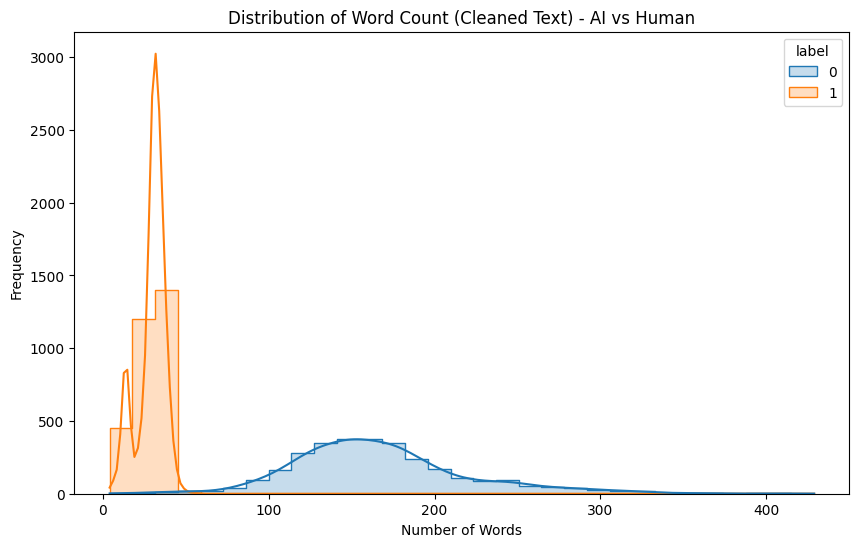

In [6]:
mapping = {'AI': 1, 'Human': 0}
df_train['label'] = df_train['Author'].map(mapping)
df_train['word_count'] = df_train['cleaned_text'].str.split().str.len()

plt.figure(figsize=(10, 6))
sns.histplot(data=df_train, x='word_count', hue='label', kde=True, element='step')
plt.title('Distribution of Word Count (Cleaned Text) - AI vs Human')
plt.xlabel('Number of Words')
plt.ylabel('Frequency')
plt.show()

In [ ]:
os.makedirs('../data/processed data', exist_ok=True)
df_train.to_csv('../data/processed data/train_cleaned.csv', index=False)
#df_test.to_csv('../data/processed data/test_cleaned.csv', index=False)